In [ ]:
print("Student Performance Prediction Project Started!")

Student Performance Prediction Project Started!


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/Sainathmudigonda/Student-Result-Analysis/main/student_exam_scores.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
  student_id  hours_studied  sleep_hours  attendance_percent  previous_scores  \
0       S001            8.0          8.8                72.1               45   
1       S002            1.3          8.6                60.7               55   
2       S003            4.0          8.2                73.7               86   
3       S004            3.5          4.8                95.1               66   
4       S005            9.1          6.4                89.8               71   

   exam_score  
0        30.2  
1        25.0  
2        35.8  
3        34.0  
4        40.3  
Dataset shape: (200, 6)
Columns: ['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores', 'exam_score']


In [ ]:
print(df.columns.tolist())
print(df.head())

['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores', 'exam_score']
  student_id  hours_studied  sleep_hours  attendance_percent  previous_scores  \
0       S001            8.0          8.8                72.1               45   
1       S002            1.3          8.6                60.7               55   
2       S003            4.0          8.2                73.7               86   
3       S004            3.5          4.8                95.1               66   
4       S005            9.1          6.4                89.8               71   

   exam_score  
0        30.2  
1        25.0  
2        35.8  
3        34.0  
4        40.3  


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Select input features
X = df[['hours_studied', 'sleep_hours',
        'attendance_percent', 'previous_scores']]

# Select target column
y = df['exam_score']

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
print("Model Training Completed!")
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Model Training Completed!
Mean Absolute Error: 2.310858235895833
R2 Score: 0.8537447137159516


In [ ]:
new_student = pd.DataFrame({
    'hours_studied': [6],
    'sleep_hours': [8],
    'attendance_percent': [85],
    'previous_scores': [75]
})

predicted_marks = model.predict(new_student)

print("Student Details:")
print(new_student)

print("Predicted Exam Score:",
      round(predicted_marks[0], 2))

Student Details:
   hours_studied  sleep_hours  attendance_percent  previous_scores
0              6            8                  85               75
Predicted Exam Score: 37.15


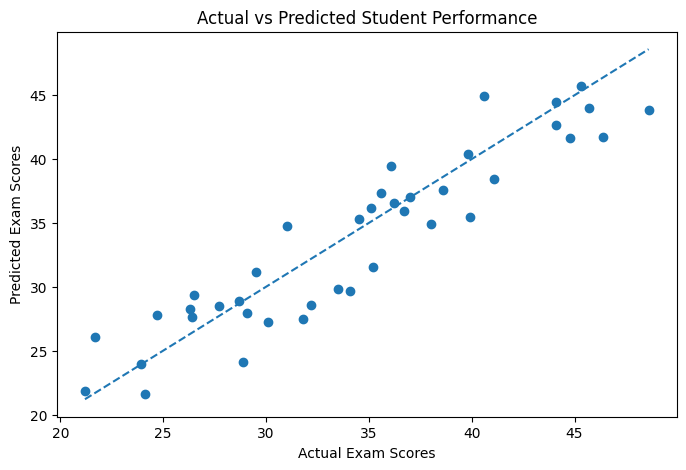

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Actual vs Predicted Student Performance")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         linestyle='--')

plt.show()